# AI Resume Analyzer and Job Recommendation System
**Unlox AI Program - Major Project 1**  |  Student: `AVILALA PAVAN RITHWIK`  |  ID: `2600031557`

This is the **core notebook**. It builds the whole project step by step:
`Upload resume -> Extract text -> Clean text -> Extract skills -> Load job roles -> TF-IDF + cosine similarity -> Match score -> Recommend roles -> Missing skills + roadmap -> Testing -> Streamlit app`

**How to run:** Runtime > Run all. No resume upload is needed (3 synthetic sample resumes are included). To test your own resume, set `USE_MY_RESUME = True` in Step 5.

## Step 0 - Install libraries

In [1]:
!pip install -q pypdf python-docx reportlab plotly streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 402.7/402.7 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 33.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 45.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 56.9 MB/s eta 0:00:00


## Step 1 - Create the project folder structure

In [2]:
import os
BASE = "ai_resume_analyzer"
for folder in ["data", "sample_resumes", "reports", "tests"]:
    os.makedirs(f"{BASE}/{folder}", exist_ok=True)
print("Folders created:", os.listdir(BASE))

Folders created: ['data', 'tests', 'reports', 'sample_resumes']


## Step 2 - Datasets (Module 4)
A small, manually verified job-role dataset and a controlled skill dictionary (58 skills, 11 categories).

In [3]:
%%writefile ai_resume_analyzer/data/job_roles.csv
role,required_skills,description
Data Analyst,python|sql|excel|pandas|power bi|data visualization|statistics,Analyses business data using SQL and Python and builds dashboards and reports for decision making
Machine Learning Engineer,python|machine learning|scikit-learn|pandas|fastapi|docker|git|mlflow,Builds trains and deploys machine learning models as reliable services
AI Engineer,python|deep learning|llm|rag|rest api|langchain|prompt engineering|docker,Builds AI applications using large language models retrieval and APIs
NLP Engineer,python|nlp|transformers|hugging face|spacy|nltk|deep learning|pytorch,Builds systems that understand text using NLP and transformer models
Computer Vision Engineer,python|opencv|cnn|yolo|deep learning|tensorflow|image processing,Builds systems that understand images and video using deep learning
Python Developer,python|flask|django|rest api|sql|git|docker|github,Builds backend applications and APIs using Python and common web frameworks
Data Scientist,python|machine learning|pandas|numpy|scikit-learn|statistics|sql|matplotlib,Explores data builds predictive models and communicates insights

Writing ai_resume_analyzer/data/job_roles.csv


In [4]:
%%writefile ai_resume_analyzer/data/skill_dictionary.csv
skill,category,aliases
python,Programming,python3
sql,Programming,
java,Programming,
c++,Programming,cpp
javascript,Programming,js
r,Programming,r programming
pandas,Data Analysis,
numpy,Data Analysis,
excel,Data Analysis,ms excel|microsoft excel|advanced excel
power bi,Data Analysis,powerbi
tableau,Data Analysis,
statistics,Data Analysis,statistical analysis|hypothesis testing
data visualization,Data Analysis,data visualisation|dashboards
data cleaning,Data Analysis,data preprocessing|data wrangling
eda,Data Analysis,exploratory data analysis
matplotlib,Data Visualization,
seaborn,Data Visualization,
plotly,Data Visualization,
machine learning,Machine Learning,ml
scikit-learn,Machine Learning,sklearn|scikit learn
deep learning,Machine Learning,neural networks
tensorflow,Machine Learning,
pytorch,Machine Learning,torch
keras,Machine Learning,
xgboost,Machine Learning,
feature engineering,Machine Learning,
mlflow,MLOps,
nlp,NLP,natural language processing
spacy,NLP,
nltk,NLP,
transformers,NLP,bert|huggingface transformers
hugging face,NLP,huggingface
tf-idf,NLP,tfidf
llm,Generative AI,llms|large language model|large language models|gpt
rag,Generative AI,retrieval augmented generation|retrieval-augmented generation
langchain,Generative AI,
prompt engineering,Generative AI,
opencv,Computer Vision,cv2
cnn,Computer Vision,cnns|convolutional neural network|convolutional neural networks
yolo,Computer Vision,yolov5|yolov8
image processing,Computer Vision,
fastapi,Backend & APIs,
flask,Backend & APIs,
django,Backend & APIs,
rest api,Backend & APIs,rest apis|restful api|apis|api
streamlit,Backend & APIs,
mysql,Databases,
postgresql,Databases,postgres
mongodb,Databases,
sqlite,Databases,
docker,Cloud & Tools,containerization
git,Cloud & Tools,
github,Cloud & Tools,
aws,Cloud & Tools,amazon web services
azure,Cloud & Tools,
gcp,Cloud & Tools,google cloud
linux,Cloud & Tools,
kubernetes,Cloud & Tools,k8s

Writing ai_resume_analyzer/data/skill_dictionary.csv


## Step 3 - Project modules
Each module is saved as its own `.py` file so the same code is reused by the Streamlit app.

In [5]:
%%writefile ai_resume_analyzer/resume_parser.py
"""Module 1 and 2: resume upload validation and text extraction (PDF and DOCX)."""
import os

from pypdf import PdfReader
import docx  # python-docx

MAX_MB = 5
ALLOWED = {".pdf", ".docx"}


def validate_file(filename: str, size_bytes: int):
    """Return (ok, message). Checks the file type and the file size."""
    ext = os.path.splitext(filename)[1].lower()
    if ext not in ALLOWED:
        return False, "Only PDF and DOCX files are supported."
    if size_bytes > MAX_MB * 1024 * 1024:
        return False, f"File is too large. Maximum size is {MAX_MB} MB."
    return True, "OK"


def extract_pdf(file_like) -> str:
    """Extract text from every PDF page."""
    reader = PdfReader(file_like)
    return "\n".join((page.extract_text() or "") for page in reader.pages)


def extract_docx(file_like) -> str:
    """Extract text from every DOCX paragraph and table cell."""
    document = docx.Document(file_like)
    parts = [p.text for p in document.paragraphs]
    for table in document.tables:
        for row in table.rows:
            for cell in row.cells:
                parts.append(cell.text)
    return "\n".join(parts)


def extract_text(file_like, filename: str) -> str:
    """Pick the right extractor from the file extension."""
    ext = os.path.splitext(filename)[1].lower()
    if ext == ".pdf":
        return extract_pdf(file_like)
    if ext == ".docx":
        return extract_docx(file_like)
    raise ValueError("Unsupported file type: " + ext)

Writing ai_resume_analyzer/resume_parser.py


In [6]:
%%writefile ai_resume_analyzer/text_cleaner.py
"""Module 2: text cleaning. Keeps C++, C#, .NET style symbols and removes personal info."""
import re

# Lines that carry protected / personal attributes are dropped before any scoring.
PERSONAL_LINE = re.compile(
    r"\b(date of birth|dob|gender|sex|marital status|religion|nationality|age|passport)\b\s*[:\-]",
    re.IGNORECASE,
)


def remove_personal_info(text: str) -> str:
    """Remove emails, URLs, phone numbers and lines with protected attributes."""
    text = re.sub(r"[\w\.-]+@[\w\.-]+\.\w+", " ", text)              # emails
    text = re.sub(r"(https?://\S+|www\.\S+)", " ", text)               # urls
    text = re.sub(r"(?:\+?\d[\s\-()]*){10,}", " ", text)               # phone numbers
    lines = [ln for ln in text.splitlines() if not PERSONAL_LINE.search(ln)]
    return "\n".join(lines)


def clean_text(text: str) -> str:
    """Lowercase, drop personal info, remove odd symbols and repeated spaces."""
    text = remove_personal_info(text).lower()
    text = re.sub(r"[\u2022\u25cf\u25aa\u25e6\u2023\u2219\u00b7]", " ", text)  # bullet symbols
    text = re.sub(r"[^a-z0-9+#./\-\n ]", " ", text)                    # keep + # . / - for C++, C#, .NET
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n\s*", "\n", text)
    return text.strip()

Writing ai_resume_analyzer/text_cleaner.py


In [7]:
%%writefile ai_resume_analyzer/skill_extractor.py
"""Module 3: controlled-dictionary skill extraction, categories and simple section detection."""
import re
from collections import defaultdict

import pandas as pd


def load_skill_dictionary(path: str) -> pd.DataFrame:
    df = pd.read_csv(path).fillna("")
    df["alias_list"] = df.apply(
        lambda r: [r["skill"].lower()] + [a.strip().lower() for a in str(r["aliases"]).split("|") if a.strip()],
        axis=1,
    )
    return df


def _pattern(alias: str):
    # Whole-term match that still works for c++, c#, .net, scikit-learn
    return re.compile(r"(?<![a-z0-9+#])" + re.escape(alias) + r"(?![a-z0-9+#])")


def extract_skills(clean_text: str, skill_df: pd.DataFrame) -> dict:
    """Return {skill: {"category": ..., "count": n}} for every dictionary skill found."""
    found = {}
    for _, row in skill_df.iterrows():
        count = sum(len(_pattern(alias).findall(clean_text)) for alias in row["alias_list"])
        if count > 0:
            found[row["skill"]] = {"category": row["category"], "count": count}
    return found


def group_by_category(found: dict) -> dict:
    grouped = defaultdict(list)
    for skill, info in found.items():
        grouped[info["category"]].append(skill)
    return {cat: sorted(skills) for cat, skills in sorted(grouped.items())}


SECTION_HEADINGS = {
    "education": {"education", "academic qualification", "academics"},
    "skills": {"skills", "technical skills", "key skills"},
    "projects": {"projects", "academic projects", "personal projects"},
    "experience": {"experience", "work experience", "internship", "internships"},
}


def detect_sections(clean_text: str) -> dict:
    """Split cleaned resume text into education / skills / projects / experience."""
    sections, current = {}, None
    for line in clean_text.splitlines():
        head = line.strip().strip(":")
        match = next((name for name, words in SECTION_HEADINGS.items() if head in words), None)
        if match:
            current = match
            sections.setdefault(current, [])
        elif current:
            sections[current].append(line)
    return {name: "\n".join(lines).strip() for name, lines in sections.items()}

Writing ai_resume_analyzer/skill_extractor.py


In [8]:
%%writefile ai_resume_analyzer/job_matcher.py
"""Module 4, 5 and 6: job-role dataset, TF-IDF + cosine matching, skill-gap analysis."""
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

W_COVERAGE = 0.7      # share of required skills found in the resume
W_SIMILARITY = 0.3    # TF-IDF cosine similarity between candidate skills and role skills


def load_roles(path: str) -> pd.DataFrame:
    df = pd.read_csv(path)
    df["skills_list"] = df["required_skills"].apply(lambda s: [x.strip().lower() for x in s.split("|")])
    return df


def _skill_doc(skills) -> str:
    # one token per skill, e.g. "power bi" -> "power_bi"
    return " ".join(s.replace(" ", "_") for s in skills)


def match_roles(clean_text: str, found_skills, roles_df: pd.DataFrame) -> pd.DataFrame:
    """Score the resume against every role and return roles ranked high to low."""
    found = set(found_skills)

    # (a) TF-IDF vectors of candidate skills and role skills -> cosine similarity
    role_docs = roles_df["skills_list"].apply(_skill_doc).tolist()
    cand_doc = _skill_doc(sorted(found))
    vec = TfidfVectorizer(analyzer=str.split)
    matrix = vec.fit_transform(role_docs + [cand_doc])
    skill_sim = cosine_similarity(matrix[-1], matrix[:-1]).ravel()

    # (b) TF-IDF vectors of the full resume text and role descriptions (shown for reference)
    role_text = (roles_df["skills_list"].apply(" ".join) + " " + roles_df["description"].str.lower()).tolist()
    vec2 = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), token_pattern=r"[a-z0-9][a-z0-9+#.\-]*")
    matrix2 = vec2.fit_transform([clean_text] + role_text)
    text_sim = cosine_similarity(matrix2[0], matrix2[1:]).ravel()

    rows = []
    for i, role in roles_df.iterrows():
        required = role["skills_list"]
        matched = [s for s in required if s in found]
        missing = [s for s in required if s not in found]
        coverage = len(matched) / len(required)
        score = 100 * (W_COVERAGE * coverage + W_SIMILARITY * skill_sim[i])
        rows.append({
            "Role": role["role"],
            "Score": round(score, 1),
            "Skill coverage %": round(100 * coverage, 1),
            "Skill similarity %": round(100 * skill_sim[i], 1),
            "Text similarity %": round(100 * text_sim[i], 1),
            "Matched": matched,
            "Missing": missing,
        })
    return pd.DataFrame(rows).sort_values("Score", ascending=False).reset_index(drop=True)


def skill_gap(found: dict, roles_df: pd.DataFrame, role_name: str) -> dict:
    """Skills present, weak (mentioned only once) and missing for one target role."""
    required = roles_df.loc[roles_df["role"] == role_name, "skills_list"].iloc[0]
    present = [s for s in required if s in found]
    weak = [s for s in present if found[s]["count"] == 1]
    missing = [s for s in required if s not in found]
    return {"required": required, "present": present, "weak": weak, "missing": missing}

Writing ai_resume_analyzer/job_matcher.py


In [9]:
%%writefile ai_resume_analyzer/roadmap_generator.py
"""Module 6 and 7: rule-based learning roadmap and downloadable text report."""

LEARNING_TOPICS = {
    "python": "Python fundamentals, functions, OOP and virtual environments",
    "sql": "SQL joins, aggregations, subqueries and window functions",
    "excel": "Excel formulas, pivot tables and charts",
    "pandas": "Pandas: cleaning, grouping, merging and reshaping data",
    "numpy": "NumPy arrays and vectorised operations",
    "power bi": "Power BI: build an interactive dashboard from a dataset",
    "statistics": "Descriptive statistics, probability and hypothesis testing",
    "data visualization": "Data visualization with Matplotlib, Seaborn or Plotly",
    "matplotlib": "Matplotlib plots and chart styling",
    "machine learning": "Supervised and unsupervised learning, model evaluation",
    "scikit-learn": "scikit-learn pipelines, train/test split and cross-validation",
    "deep learning": "Neural networks, backpropagation and training with PyTorch or TensorFlow",
    "tensorflow": "TensorFlow / Keras: build and train a small model",
    "pytorch": "PyTorch tensors, datasets and training loops",
    "fastapi": "FastAPI basics: build and test a REST API",
    "flask": "Flask basics: routes, templates and a small web app",
    "django": "Django basics: models, views and the admin panel",
    "rest api": "REST API design: methods, status codes and JSON",
    "docker": "Docker fundamentals: images, containers and Dockerfiles",
    "git": "Git workflow: commits, branches and pull requests",
    "github": "GitHub: publish a repository with a good README",
    "mlflow": "MLflow experiment tracking and model registry",
    "nlp": "NLP basics: tokenisation, TF-IDF, embeddings and text classification",
    "spacy": "spaCy pipelines, NER and phrase matching",
    "nltk": "NLTK text preprocessing and basic analysis",
    "transformers": "Transformer models and fine-tuning with Hugging Face",
    "hugging face": "Hugging Face pipelines, datasets and model hub",
    "llm": "LLM basics: prompting, APIs and evaluation",
    "rag": "Retrieval-Augmented Generation: embeddings, vector search and a RAG demo",
    "langchain": "LangChain chains, tools and retrievers",
    "prompt engineering": "Prompt engineering patterns and controlled prompts",
    "opencv": "OpenCV image reading, filtering and feature detection",
    "cnn": "Convolutional neural networks for image classification",
    "yolo": "YOLO object detection: train and run a detector",
    "image processing": "Image processing: filters, thresholding and transformations",
}


def topic_for(skill: str) -> str:
    return LEARNING_TOPICS.get(skill, f"Learn the basics of {skill} and use it in a small project")


def generate_roadmap(missing, weak=None, per_week: int = 2):
    """Return a list of (week_label, text). Missing skills first, then a mini-project week."""
    weak = weak or []
    plan, week = [], 1
    for i in range(0, len(missing), per_week):
        chunk = missing[i:i + per_week]
        plan.append((f"Week {week}", "; ".join(topic_for(s) for s in chunk)))
        week += 1
    if weak:
        plan.append((f"Week {week}", "Strengthen with practice projects: " + ", ".join(weak)))
        week += 1
    if missing or weak:
        plan.append((f"Week {week}", "Build one small project that uses " + ", ".join((missing + weak)[:4]) + " and add it to your resume"))
    return plan


def build_report(target_role, ranking, found_by_category, gap, roadmap) -> str:
    top3 = ranking.head(3)
    target_row = ranking[ranking["Role"] == target_role].iloc[0]
    lines = ["AI RESUME ANALYSIS REPORT", "=" * 26, "",
             f"Target role: {target_role}",
             f"Resume match score: {target_row['Score']}%", "",
             "Skills found:"]
    for cat, skills in found_by_category.items():
        lines.append(f"  {cat}: {', '.join(skills)}")
    lines += ["", "Missing skills: " + (", ".join(gap["missing"]) or "none"),
              "Weak skills (mentioned once): " + (", ".join(gap["weak"]) or "none"), "",
              "Recommended roles:"]
    for i, r in enumerate(top3.itertuples(), 1):
        lines.append(f"  {i}. {r.Role} - {r.Score}%")
    lines += ["", "Suggested roadmap:"]
    lines += [f"  {w}: {t}" for w, t in roadmap]
    lines += ["", "NOTE: Match scores are estimates for learning guidance, not recruiter decisions.",
              "Missing keywords do not always mean missing ability."]
    return "\n".join(lines)

Writing ai_resume_analyzer/roadmap_generator.py


## Step 4 - Synthetic sample resumes (personal details are fake)

In [10]:
%%writefile ai_resume_analyzer/sample_resumes/resume_A.txt
Sample Candidate A
Email: candidate.a@example.com | Phone: +91 98765 43210
Gender: Female
Date of Birth: 01-01-2003

EDUCATION
B.Tech in Computer Science, 2021 - 2025

SKILLS
Python, SQL, Excel, Pandas, NumPy, Power BI, Tableau, Matplotlib, Statistics, Data Visualization

PROJECTS
- Sales Dashboard: built an interactive Power BI dashboard and cleaned data using Pandas and SQL.
- Exploratory data analysis on retail data using Python, Matplotlib and Seaborn.

EXPERIENCE
Data Analyst Intern: wrote SQL queries, prepared Excel reports and presented insights to managers.

Writing ai_resume_analyzer/sample_resumes/resume_A.txt


In [11]:
%%writefile ai_resume_analyzer/sample_resumes/resume_B.txt
Sample Candidate B
Email: candidate.b@example.com | Phone: +91 91234 56789
Nationality: Indian
Marital Status: Single

EDUCATION
B.Tech in Artificial Intelligence, 2021 - 2025

SKILLS
Python, Machine Learning, scikit-learn, Pandas, NumPy, XGBoost, FastAPI, Docker, Git, GitHub, Feature Engineering

PROJECTS
- Customer churn prediction: trained models with scikit-learn and XGBoost, tracked results and served the model through a FastAPI REST API.
- Packaged the service with Docker and published the code on GitHub.

EXPERIENCE
Machine Learning Intern: built and evaluated ML models and deployed them as APIs.

Writing ai_resume_analyzer/sample_resumes/resume_B.txt


In [12]:
%%writefile ai_resume_analyzer/sample_resumes/resume_C.txt
Sample Candidate C
Email: candidate.c@example.com | Phone: +91 90000 11111
Age: 22

EDUCATION
B.Tech in Artificial Intelligence, 2021 - 2025

SKILLS
Python, NLP, spaCy, NLTK, Transformers, Hugging Face, PyTorch, Deep Learning, TF-IDF

PROJECTS
- Sentiment classifier: fine-tuned a BERT transformer with Hugging Face and PyTorch.
- Text preprocessing pipeline using NLTK and spaCy with TF-IDF features.

EXPERIENCE
NLP Intern: worked on named entity recognition and text classification using natural language processing.

Writing ai_resume_analyzer/sample_resumes/resume_C.txt


## Step 5 - Resume upload, text extraction and cleaning (Modules 1 and 2)

In [13]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, BASE)

from resume_parser import extract_text, validate_file
from text_cleaner import clean_text
from skill_extractor import load_skill_dictionary, extract_skills, group_by_category, detect_sections
from job_matcher import load_roles, match_roles, skill_gap
from roadmap_generator import generate_roadmap, build_report

skill_df = load_skill_dictionary(f"{BASE}/data/skill_dictionary.csv")
roles_df = load_roles(f"{BASE}/data/job_roles.csv")
print(f"Skill dictionary: {len(skill_df)} skills | Job roles: {len(roles_df)}")

Skill dictionary: 58 skills | Job roles: 7


In [14]:
# Build a real DOCX and a real PDF from a sample resume to prove both parsers work
import docx
from reportlab.lib.pagesizes import A4
from reportlab.pdfgen import canvas

sample_text = open(f"{BASE}/sample_resumes/resume_B.txt").read()

d = docx.Document()
for line in sample_text.splitlines():
    d.add_paragraph(line)
d.save(f"{BASE}/sample_resumes/resume_B.docx")

pdf = canvas.Canvas(f"{BASE}/sample_resumes/resume_B.pdf", pagesize=A4)
y = 800
for line in sample_text.splitlines():
    pdf.drawString(40, y, line)
    y -= 16
pdf.save()

for fname in ["resume_B.pdf", "resume_B.docx"]:
    path = f"{BASE}/sample_resumes/{fname}"
    ok, msg = validate_file(fname, os.path.getsize(path))
    text = extract_text(path, fname)
    print(f"{fname}: validation={ok} ({msg}) | characters extracted = {len(text)}")

raw_text = extract_text(f"{BASE}/sample_resumes/resume_B.pdf", "resume_B.pdf")
clean = clean_text(raw_text)
print("\n--- RAW TEXT (first 350 chars) ---\n" + raw_text[:350])
print("\n--- CLEANED TEXT (first 350 chars) ---\n" + clean[:350])

resume_B.pdf: validation=True (OK) | characters extracted = 607
resume_B.docx: validation=True (OK) | characters extracted = 610

--- RAW TEXT (first 350 chars) ---
Sample Candidate B
Email: candidate.b@example.com | Phone: +91 91234 56789
Nationality: Indian
Marital Status: Single
EDUCATION
B.Tech in Artificial Intelligence, 2021 - 2025
SKILLS
Python, Machine Learning, scikit-learn, Pandas, NumPy, XGBoost, FastAPI, Docker, Git, GitHub, Feature Engineering
PROJECTS
- Customer churn prediction: trained models w

--- CLEANED TEXT (first 350 chars) ---
sample candidate b
education
b.tech in artificial intelligence 2021 - 2025
skills
python machine learning scikit-learn pandas numpy xgboost fastapi docker git github feature engineering
projects
- customer churn prediction trained models with scikit-learn and xgboost tracked results and served the model through a fastapi rest api.
- packaged the se


In [15]:
# OPTIONAL: analyse YOUR OWN resume in Colab (PDF or DOCX)
USE_MY_RESUME = False

if USE_MY_RESUME:
    from google.colab import files
    uploaded = files.upload()
    my_file = list(uploaded.keys())[0]
    with open(my_file, "wb") as f:
        f.write(uploaded[my_file])
    raw_text = extract_text(my_file, my_file)
    clean = clean_text(raw_text)
    print("Loaded:", my_file)

## Step 6 - Skill extraction (Module 3)

In [16]:
sections = detect_sections(clean)
print("Sections detected:", list(sections))

found = extract_skills(clean, skill_df)
grouped = group_by_category(found)
print(f"Skills identified: {len(found)} (dictionary contains {len(skill_df)} skills)\n")
for category, skills in grouped.items():
    print(f"{category:18s}: {', '.join(skills)}")

Sections detected: ['education', 'skills', 'projects', 'experience']
Skills identified: 12 (dictionary contains 58 skills)

Backend & APIs    : fastapi, rest api
Cloud & Tools     : docker, git, github
Data Analysis     : numpy, pandas
Machine Learning  : feature engineering, machine learning, scikit-learn, xgboost
Programming       : python


## Step 7 - Matching and role recommendation (Module 5)
`Score = 70% x skill coverage + 30% x TF-IDF cosine similarity` (candidate skills vs role skills). Full-text TF-IDF similarity is shown for reference.

,Role,Score,Skill coverage %,Skill similarity %,Text similarity %
0,Machine Learning Engineer,78.9,87.5,58.7,26.2
1,Data Scientist,55.9,62.5,40.5,13.7
2,Python Developer,55.5,62.5,39.3,5.3
3,AI Engineer,31.4,37.5,17.1,5.8
4,Data Analyst,22.9,28.6,9.6,1.2
5,Computer Vision Engineer,10.7,14.3,2.5,2.1
6,NLP Engineer,9.4,12.5,2.3,2.3


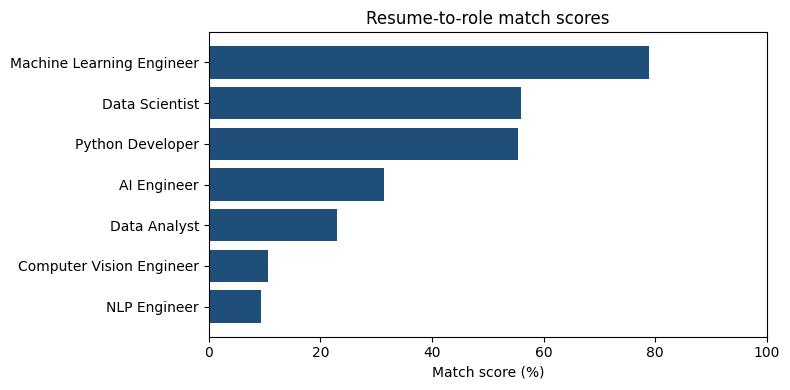

Top 3 recommended roles:
  1. Machine Learning Engineer - 78.9%
  2. Data Scientist - 55.9%
  3. Python Developer - 55.5%


In [17]:
ranking = match_roles(clean, list(found), roles_df)
display(ranking[["Role", "Score", "Skill coverage %", "Skill similarity %", "Text similarity %"]])

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(ranking["Role"][::-1], ranking["Score"][::-1], color="#1f4e79")
ax.set_xlim(0, 100)
ax.set_xlabel("Match score (%)")
ax.set_title("Resume-to-role match scores")
plt.tight_layout()
plt.show()

print("Top 3 recommended roles:")
for i, row in enumerate(ranking.head(3).itertuples(), 1):
    print(f"  {i}. {row.Role} - {row.Score}%")

## Step 8 - Skill-gap analysis, learning roadmap and report (Module 6)

In [18]:
TARGET_ROLE = "Machine Learning Engineer"

gap = skill_gap(found, roles_df, TARGET_ROLE)
roadmap = generate_roadmap(gap["missing"], gap["weak"])
report = build_report(TARGET_ROLE, ranking, grouped, gap, roadmap)

with open(f"{BASE}/reports/analysis_report.txt", "w") as f:
    f.write(report)
print(report)

AI RESUME ANALYSIS REPORT

Target role: Machine Learning Engineer
Resume match score: 78.9%

Skills found:
  Backend & APIs: fastapi, rest api
  Cloud & Tools: docker, git, github
  Data Analysis: numpy, pandas
  Machine Learning: feature engineering, machine learning, scikit-learn, xgboost
  Programming: python

Missing skills: mlflow
Weak skills (mentioned once): python, pandas, git

Recommended roles:
  1. Machine Learning Engineer - 78.9%
  2. Data Scientist - 55.9%
  3. Python Developer - 55.5%

Suggested roadmap:
  Week 1: MLflow experiment tracking and model registry
  Week 2: Strengthen with practice projects: python, pandas, git
  Week 3: Build one small project that uses mlflow, python, pandas, git and add it to your resume

NOTE: Match scores are estimates for learning guidance, not recruiter decisions.
Missing keywords do not always mean missing ability.


## Step 9 - Workflow / architecture diagram

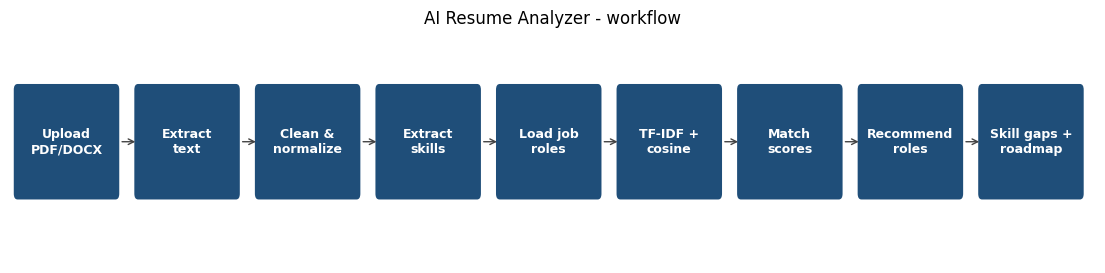

In [19]:
from matplotlib.patches import FancyBboxPatch

steps = ["Upload\nPDF/DOCX", "Extract\ntext", "Clean &\nnormalize", "Extract\nskills",
         "Load job\nroles", "TF-IDF +\ncosine", "Match\nscores", "Recommend\nroles", "Skill gaps +\nroadmap"]
fig, ax = plt.subplots(figsize=(14, 3))
ax.set_xlim(0, len(steps) * 1.6)
ax.set_ylim(0, 2)
ax.axis("off")
for i, s in enumerate(steps):
    x = i * 1.6 + 0.1
    ax.add_patch(FancyBboxPatch((x, 0.6), 1.3, 0.9, boxstyle="round,pad=0.05", fc="#1f4e79", ec="none"))
    ax.text(x + 0.65, 1.05, s, ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    if i < len(steps) - 1:
        ax.annotate("", xy=(x + 1.6, 1.05), xytext=(x + 1.35, 1.05), arrowprops=dict(arrowstyle="->", color="#444"))
ax.set_title("AI Resume Analyzer - workflow", fontsize=12)
plt.savefig(f"{BASE}/reports/workflow_diagram.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 10 - Testing and evaluation sheet

In [20]:
tests = [("Resume A", "resume_A.txt", "Data Analyst"),
         ("Resume B", "resume_B.txt", "Machine Learning Engineer"),
         ("Resume C", "resume_C.txt", "NLP Engineer")]

def analyse(text):
    c = clean_text(text)
    f = extract_skills(c, skill_df)
    return match_roles(c, list(f), roles_df), f

rows = []
for name, fname, expected in tests:
    text = open(f"{BASE}/sample_resumes/{fname}").read()
    r, f = analyse(text)
    actual = r.loc[0, "Role"]
    rows.append({"Test Resume": name, "Expected Top Role": expected, "Actual Top Role": actual,
                 "Top Score %": r.loc[0, "Score"], "Skills Found": len(f),
                 "Result": "PASS" if actual == expected else "CHECK"})
test_df = pd.DataFrame(rows)
test_df.to_csv(f"{BASE}/tests/test_cases.csv", index=False)
display(test_df)

,Test Resume,Expected Top Role,Actual Top Role,Top Score %,Skills Found,Result
0,Resume A,Data Analyst,Data Analyst,90.1,12,PASS
1,Resume B,Machine Learning Engineer,Machine Learning Engineer,78.9,12,PASS
2,Resume C,NLP Engineer,NLP Engineer,97.3,9,PASS


In [21]:
# Score consistency: score should change logically when skills are added or removed
text_a = open(f"{BASE}/sample_resumes/resume_A.txt").read()
base, _ = analyse(text_a)
def score(df, role): return df.loc[df["Role"] == role, "Score"].iloc[0]

removed, _ = analyse(text_a.replace("Power BI", "").replace("Tableau", ""))
added, _ = analyse(text_a + "\nSkills: Machine Learning, scikit-learn, Docker, FastAPI, Git, MLflow")

print("Data Analyst score  - original :", score(base, "Data Analyst"))
print("Data Analyst score  - Power BI removed:", score(removed, "Data Analyst"),
      "-> PASS (drops)" if score(removed, "Data Analyst") < score(base, "Data Analyst") else "-> CHECK")
print("ML Engineer score   - original :", score(base, "Machine Learning Engineer"))
print("ML Engineer score   - ML skills added :", score(added, "Machine Learning Engineer"),
      "-> PASS (rises)" if score(added, "Machine Learning Engineer") > score(base, "Machine Learning Engineer") else "-> CHECK")

# Fairness: protected personal details must not change the score
extra = "\nGender: Male\nDate of Birth: 05-05-1999\nNationality: Indian\nMarital Status: Married\nReligion: Example"
fair, _ = analyse(text_a + extra)
same = score(fair, "Data Analyst") == score(base, "Data Analyst")
print("\nFairness test (gender, DOB, nationality, marital status, religion added):",
      "PASS - score unchanged" if same else "CHECK - score changed")

Data Analyst score  - original : 90.1
Data Analyst score  - Power BI removed: 77.5 -> PASS (drops)
ML Engineer score   - original : 20.1
ML Engineer score   - ML skills added : 87.7 -> PASS (rises)

Fairness test (gender, DOB, nationality, marital status, religion added): PASS - score unchanged


## Step 11 - Streamlit application files (Module 7)
These cells write `app.py`, `requirements.txt`, `.gitignore` and `README.md`. Run the app locally with `streamlit run app.py` or deploy it from GitHub on Streamlit Community Cloud.

In [22]:
%%writefile ai_resume_analyzer/app.py
"""Module 7: Streamlit dashboard for the AI Resume Analyzer and Job Recommendation System."""
import io
import os

import pandas as pd
import plotly.express as px
import streamlit as st

from resume_parser import extract_text, validate_file
from text_cleaner import clean_text
from skill_extractor import load_skill_dictionary, extract_skills, group_by_category
from job_matcher import load_roles, match_roles, skill_gap
from roadmap_generator import generate_roadmap, build_report

BASE = os.path.dirname(os.path.abspath(__file__))

st.set_page_config(page_title="AI Resume Analyzer", page_icon="📄", layout="wide")
st.title("AI Resume Analyzer and Job Recommendation System")
st.caption("Upload your resume, pick a target role and see your match score, missing skills and a learning roadmap.")


@st.cache_data
def load_data():
    roles = load_roles(os.path.join(BASE, "data", "job_roles.csv"))
    skills = load_skill_dictionary(os.path.join(BASE, "data", "skill_dictionary.csv"))
    return roles, skills


roles_df, skill_df = load_data()

with st.sidebar:
    st.header("1. Upload and choose")
    uploaded = st.file_uploader("Resume (PDF or DOCX, max 5 MB)", type=["pdf", "docx"])
    target = st.selectbox("Target role", roles_df["role"].tolist())
    st.info("Your resume is processed in memory only and is not stored.")

if uploaded is None:
    st.write("Upload a resume from the sidebar to begin.")
    st.stop()

ok, message = validate_file(uploaded.name, uploaded.size)
if not ok:
    st.error(message)
    st.stop()
st.success(f"Uploaded file: {uploaded.name}")

try:
    raw_text = extract_text(io.BytesIO(uploaded.getvalue()), uploaded.name)
except Exception as exc:
    st.error(f"Could not read this file: {exc}")
    st.stop()

clean = clean_text(raw_text)
if len(clean) < 50:
    st.warning("Very little text was found. The file may be a scanned image, so skills may be missed.")

found = extract_skills(clean, skill_df)
grouped = group_by_category(found)
ranking = match_roles(clean, list(found), roles_df)
gap = skill_gap(found, roles_df, target)
roadmap = generate_roadmap(gap["missing"], gap["weak"])
target_score = ranking.loc[ranking["Role"] == target, "Score"].iloc[0]

tab1, tab2, tab3, tab4 = st.tabs(["Extracted skills", "Match scores", "Gap and roadmap", "Report"])

with tab1:
    st.subheader(f"{len(found)} skills found")
    for category, skills in grouped.items():
        st.markdown(f"**{category}:** " + ", ".join(skills))

with tab2:
    st.metric(f"Match score for {target}", f"{target_score}%")
    fig = px.bar(ranking, x="Score", y="Role", orientation="h", range_x=[0, 100], text="Score")
    fig.update_layout(yaxis={"categoryorder": "total ascending"})
    st.plotly_chart(fig, use_container_width=True)
    st.subheader("Top 3 recommended roles")
    for i, row in enumerate(ranking.head(3).itertuples(), 1):
        st.write(f"{i}. **{row.Role}** - {row.Score}%")
    st.caption("Scores are estimates for learning guidance, not recruiter decisions.")

with tab3:
    c1, c2 = st.columns(2)
    c1.subheader("Already in your resume")
    c1.write(", ".join(gap["present"]) or "None")
    c2.subheader("Missing skills")
    c2.write(", ".join(gap["missing"]) or "None - great coverage!")
    if gap["weak"]:
        st.write("Weak (mentioned only once): " + ", ".join(gap["weak"]))
    st.subheader("Learning roadmap")
    for week, text in roadmap:
        st.write(f"**{week}:** {text}")
    st.caption("Missing keywords do not always mean missing ability.")

with tab4:
    report = build_report(target, ranking, grouped, gap, roadmap)
    st.text(report)
    st.download_button("Download analysis report", report, file_name="resume_analysis_report.txt")

Writing ai_resume_analyzer/app.py


In [23]:
%%writefile ai_resume_analyzer/requirements.txt
streamlit
pandas
numpy
scikit-learn
pypdf
python-docx
plotly
matplotlib

Writing ai_resume_analyzer/requirements.txt


In [24]:
%%writefile ai_resume_analyzer/.gitignore
.env
__pycache__/
*.pyc
reports/*
!reports/.gitkeep
.venv/
.ipynb_checkpoints/

Writing ai_resume_analyzer/.gitignore


In [25]:
%%writefile ai_resume_analyzer/README.md
# AI Resume Analyzer and Job Recommendation System

An NLP-based Streamlit application that helps students see how well their resume matches selected job roles. It extracts text from PDF/DOCX resumes, identifies technical skills, scores the resume against job roles, recommends the top 3 roles, lists missing skills and generates a simple learning roadmap.

> Built for the Unlox AI Program - Major Project 1.

## Features
- Upload a PDF or DOCX resume (file type and size validated, nothing stored permanently)
- Text extraction (`pypdf`, `python-docx`) and cleaning (regex; keeps C++, C#, .NET)
- Skill extraction from a controlled dictionary of 58 skills in 11 categories
- Comparison with 7 job roles (Data Analyst, ML Engineer, AI Engineer, NLP Engineer, Computer Vision Engineer, Python Developer, Data Scientist)
- Match score, ranked roles, top-3 recommendation and chart
- Skill-gap analysis (present / weak / missing) and a rule-based weekly roadmap
- Downloadable text report

## Workflow
Upload resume -> Extract text -> Clean text -> Extract skills -> Load role requirements -> TF-IDF + cosine similarity -> Match score -> Recommend roles -> Missing skills + roadmap

## How the match score works
`Score = 70% x skill coverage + 30% x TF-IDF cosine similarity (candidate skills vs role skills)`
- Skill coverage = required skills found in the resume / required skills for the role
- TF-IDF cosine similarity gives more weight to less common skills
- Full-text TF-IDF similarity between the resume and the role description is also shown for reference

## Setup
```bash
git clone <your-repo-url>
cd ai_resume_analyzer
pip install -r requirements.txt
streamlit run app.py
```

## Project structure
```
ai_resume_analyzer/
|-- app.py                 Streamlit dashboard
|-- resume_parser.py       PDF/DOCX extraction and validation
|-- text_cleaner.py        Cleaning and personal-information removal
|-- skill_extractor.py     Dictionary skill extraction, categories, sections
|-- job_matcher.py         TF-IDF, cosine similarity, skill-gap analysis
|-- roadmap_generator.py   Learning roadmap and report
|-- requirements.txt
|-- data/ (job_roles.csv, skill_dictionary.csv)
|-- sample_resumes/        Synthetic resumes (no real personal data)
|-- reports/
|-- tests/test_cases.csv   Testing sheet
```

## Testing
Three sample resumes were tested; each returns the expected top role (see `tests/test_cases.csv`). Score-consistency and fairness checks are in the Colab notebook.

## Responsible AI
- Guidance tool only, not for hiring or rejection decisions
- Gender, age, religion, nationality, marital status, photo and disability are never scored (such lines are removed before analysis)
- Only job-related skills, education, projects and experience are evaluated
- Scores are estimates; missing keywords do not always mean missing ability
- Uploaded resumes are processed in memory and not stored

## Limitations
- Keyword/dictionary matching misses skills that are not in the dictionary or are written differently
- Only 7 roles and 58 skills; role requirements are manually defined
- Scanned (image) PDFs cannot be read without OCR
- TF-IDF does not understand meaning (Sentence Transformers could be added as an improvement)

## Deployment
Push the repository to GitHub and deploy on Streamlit Community Cloud (main file: `app.py`).

## Author
<Your Name> - Unlox AI Program

Writing ai_resume_analyzer/README.md


In [26]:
# OPTIONAL: preview the Streamlit app inside Colab (needs a tunnel; skip if it does not work)
# !streamlit run ai_resume_analyzer/app.py &>/content/streamlit.log &
# !npx localtunnel --port 8501
print("Recommended: push the ai_resume_analyzer folder to GitHub and deploy on Streamlit Community Cloud.")

Recommended: push the ai_resume_analyzer folder to GitHub and deploy on Streamlit Community Cloud.


## Step 12 - Summary, responsible AI and limitations
**What was built:** a complete NLP pipeline (PDF/DOCX extraction, regex cleaning, dictionary skill extraction, TF-IDF + cosine matching, skill-gap analysis, rule-based roadmap) with a Streamlit dashboard.

**Responsible AI:** guidance only (not for hiring); gender, age, religion, nationality, marital status are removed before scoring; scores are estimates; missing keywords do not always mean missing ability; resumes are processed in memory and not stored.

**Limitations:** dictionary matching misses unlisted or differently written skills; only 7 roles / 58 skills; scanned PDFs need OCR; TF-IDF does not understand meaning.

**Future improvements:** spaCy phrase matching, Sentence Transformers for semantic matching, job-description upload, FastAPI backend, database and Docker deployment.